# Testing Data Pulls

In [1]:
import polars as pl
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import dates as mdates
from matplotlib.ticker import StrMethodFormatter

from miso_forecasting.ingestion.eia import ingest_eia
from miso_forecasting.ingestion.miso import ingest_miso
from miso_forecasting.ingestion.noaa import ingest_noaa

## EIA

In [2]:
# Fetch data in the format Year-Month-Day-Time from 00 to 23
eia_df = ingest_eia(
    start_date="2025-01-15T00",
    end_date="2025-01-15T23",
    respondent="MISO",
    series_type="D",
    output_path = "../data/raw/eia/eia_2025-01-15.parquet"
)

eia_df.head(5)

period,respondent,respondent-name,type,type-name,value,value-units
str,str,str,str,str,str,str
"""2025-01-15T00""","""MISO""","""Midcontinent Independent Syste…","""D""","""Demand""","""89562""","""megawatthours"""
"""2025-01-15T01""","""MISO""","""Midcontinent Independent Syste…","""D""","""Demand""","""90774""","""megawatthours"""
"""2025-01-15T02""","""MISO""","""Midcontinent Independent Syste…","""D""","""Demand""","""90489""","""megawatthours"""
"""2025-01-15T03""","""MISO""","""Midcontinent Independent Syste…","""D""","""Demand""","""89161""","""megawatthours"""
"""2025-01-15T04""","""MISO""","""Midcontinent Independent Syste…","""D""","""Demand""","""86766""","""megawatthours"""


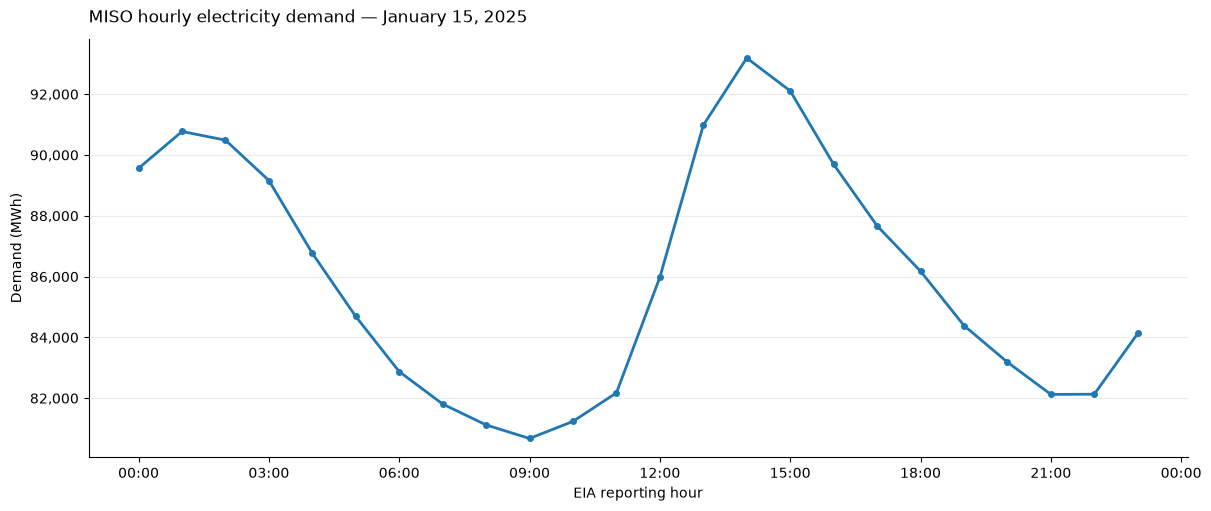

In [3]:
plot_df = (
    eia_df.with_columns(
        pl.concat_str([pl.col("period"), pl.lit(":00")])
        .str.strptime(pl.Datetime, format="%Y-%m-%dT%H:%M")
        .alias("reporting_hour"),
        pl.col("value")
        .cast(pl.Float64, strict=False)
        .alias("demand_mwh"),
    )
    .sort("reporting_hour")
)

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")

ax.plot(
    plot_df["reporting_hour"].to_list(),
    plot_df["demand_mwh"].to_list(),
    linewidth=2,
    marker="o",
    markersize=4,
    color="tab:blue",
)

# Extract the first and last dates from the dataset
first_day = plot_df["reporting_hour"].min().strftime("%B %d, %Y")
last_day = plot_df["reporting_hour"].max().strftime("%B %d, %Y")
if first_day == last_day:
    date_label = first_day
else:
    date_label = f"{first_day} - {last_day}"

ax.set_title(
    f"MISO hourly electricity demand — {date_label}",
    loc="left",
    pad=12,
)
ax.set_xlabel("EIA reporting hour")
ax.set_ylabel("Demand (MWh)")

# Show one x-axis label every three hours, with no rotated text.
ax.xaxis.set_major_locator(mdates.HourLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.show()


## MISO Markets

In [4]:
miso_df = ingest_miso(
    market_date="2025-01-15",
    output_path="../data/raw/miso/miso_2025-01-15.parquet",
    node="MINN.HUB",
)
miso_df.head(5)

Node,Type,hour_ending,LMP,MCC,MLC,market_date,interval_start_utc,energy
str,str,i8,f64,f64,f64,date,"datetime[μs, UTC]",f64
"""MINN.HUB""","""Hub""",1,74.14,1.57,2.19,2025-01-15,2025-01-15 05:00:00 UTC,70.38
"""MINN.HUB""","""Hub""",2,65.88,1.43,3.47,2025-01-15,2025-01-15 06:00:00 UTC,60.98
"""MINN.HUB""","""Hub""",3,45.3,-4.44,-1.51,2025-01-15,2025-01-15 07:00:00 UTC,51.25
"""MINN.HUB""","""Hub""",4,44.38,-6.62,1.74,2025-01-15,2025-01-15 08:00:00 UTC,49.26
"""MINN.HUB""","""Hub""",5,40.56,-12.22,2.86,2025-01-15,2025-01-15 09:00:00 UTC,49.92


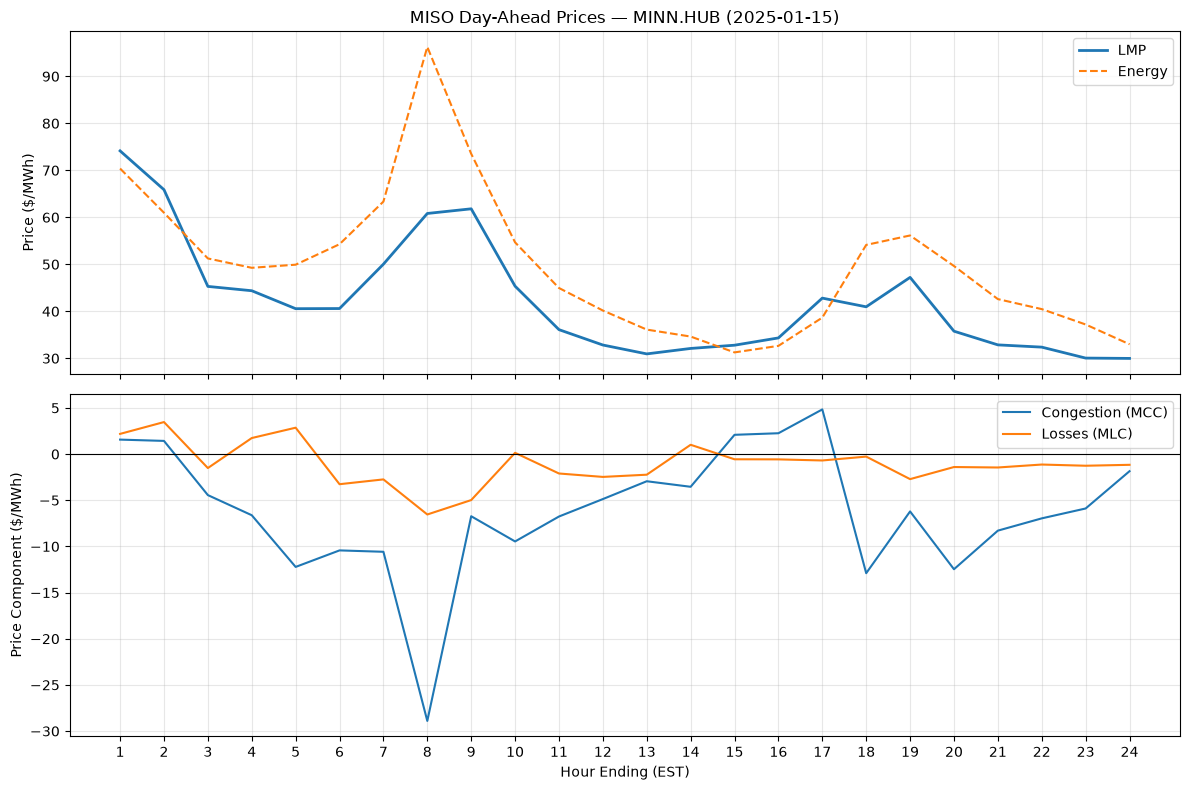

In [5]:
hours = miso_df["hour_ending"].to_numpy()

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
)

# Plot 1: LMP and implied energy component
axes[0].plot(hours, miso_df["LMP"], label="LMP", linewidth=2)
axes[0].plot(hours, miso_df["energy"], label="Energy", linestyle="--")

axes[0].set_title("MISO Day-Ahead Prices — MINN.HUB (2025-01-15)")
axes[0].set_ylabel("Price ($/MWh)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Congestion and loss components
axes[1].plot(hours, miso_df["MCC"], label="Congestion (MCC)")
axes[1].plot(hours, miso_df["MLC"], label="Losses (MLC)")

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Hour Ending (EST)")
axes[1].set_ylabel("Price Component ($/MWh)")
axes[1].set_xticks(range(1, 25))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## NOAA Weather

In [ ]:
station = "USW00014922"
start_date = "2025-01-15"
end_date = "2025-01-15"

output = Path(f"../data/raw/noaa/noaa_{station}_{start_date}.parquet")

noaa_df = ingest_noaa(
    start_date=start_date,
    end_date=end_date,
    output_path=output,
    station=station,
)

print(noaa_df.shape)
print(noaa_df.columns)
print(noaa_df.head(5))

Downloading: https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly/access/by-year/2025/parquet/GHCNh_USW00014922_2025.parquet
Downloaded 13260 rows for 2025
Saved 47 observations to data/raw/noaa/noaa_USW00014922_2025-01-15.parquet
(47, 329)
['STATION', 'Station_name', 'DATE', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'temperature', 'temperature_Measurement_Code', 'temperature_Quality_Code', 'temperature_Report_Type', 'temperature_Source_Code', 'temperature_Source_Station_ID', 'dew_point_temperature', 'dew_point_temperature_Measurement_Code', 'dew_point_temperature_Quality_Code', 'dew_point_temperature_Report_Type', 'dew_point_temperature_Source_Code', 'dew_point_temperature_Source_Station_ID', 'station_level_pressure', 'station_level_pressure_Measurement_Code', 'station_level_pressure_Quality_Code', 'station_level_pressure_Report_Type', 'station_level_pressure_Source_Code', 'station_level_pressure_Source_Station_ID', 'sea_level